In [3]:
import pandas as pd

# Load the SMS Spam Collection dataset directly
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

df = pd.read_csv(
    url,
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
df.describe(include="all")

,label,message
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


In [5]:
df.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB


In [6]:
print(df.isnull().sum())

label      0
message    0
dtype: int64


In [7]:
print(df.duplicated().sum())

403


In [8]:
print(df["label"].value_counts())

label
ham     4825
spam     747
Name: count, dtype: int64


In [9]:
df=df.drop_duplicates()

In [10]:
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (5169, 2)


In [11]:
print(df["label"].value_counts())

label
ham     4516
spam     653
Name: count, dtype: int64


In [12]:
# Calculate the percentage of each label
print(df["label"].value_counts(normalize=True) * 100)

label
ham     87.366996
spam    12.633004
Name: proportion, dtype: float64


In [13]:
# Examine examples of legitimate messages
print("HAM EXAMPLES:")
print(df[df["label"] == "ham"]["message"].head(5))

# Examine examples of spam messages
print("\nSPAM EXAMPLES:")
print(df[df["label"] == "spam"]["message"].head(5))

HAM EXAMPLES:
0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
6    Even my brother is not like to speak with me. ...
Name: message, dtype: str

SPAM EXAMPLES:
2     Free entry in 2 a wkly comp to win FA Cup fina...
5     FreeMsg Hey there darling it's been 3 week's n...
8     WINNER!! As a valued network customer you have...
9     Had your mobile 11 months or more? U R entitle...
11    SIX chances to win CASH! From 100 to 20,000 po...
Name: message, dtype: str


In [14]:
# Separate the features and target
X = df["message"]
y = df["label"]

# Check their shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Inspect a few examples
print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())

Features shape: (5169,)
Target shape: (5169,)

Features:
0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: message, dtype: str

Target:
0     ham
1     ham
2    spam
3     ham
4     ham
Name: label, dtype: str


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (4135,)
Testing features: (1034,)
Training targets: (4135,)
Testing targets: (1034,)


In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the vectorizer
vectorizer = TfidfVectorizer()

# Learn vocabulary and calculate TF-IDF values from training messages
X_train_tfidf = vectorizer.fit_transform(X_train)

# Transform test messages using the learned vocabulary
X_test_tfidf = vectorizer.transform(X_test)

# Inspect the results
print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)
print("Number of learned words:", len(vectorizer.vocabulary_))

Training matrix shape: (4135, 7680)
Testing matrix shape: (1034, 7680)
Number of learned words: 7680


In [17]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create a simple baseline that always predicts the most frequent class
baseline = DummyClassifier(strategy="most_frequent")

# Train the baseline
baseline.fit(X_train_tfidf, y_train)

# Predict the test labels
y_baseline_pred = baseline.predict(X_test_tfidf)

# Evaluate the baseline
print("Baseline Accuracy:", accuracy_score(y_test, y_baseline_pred))

print("\nBaseline Classification Report:")
print(classification_report(y_test, y_baseline_pred, zero_division=0))

Baseline Accuracy: 0.8733075435203095

Baseline Classification Report:
              precision    recall  f1-score   support

         ham       0.87      1.00      0.93       903
        spam       0.00      0.00      0.00       131

    accuracy                           0.87      1034
   macro avg       0.44      0.50      0.47      1034
weighted avg       0.76      0.87      0.81      1034



In [18]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

# Create the model
nb_model = MultinomialNB()

# Train the model using our TF-IDF features
nb_model.fit(X_train_tfidf, y_train)

# Predict labels for unseen test messages
y_pred = nb_model.predict(X_test_tfidf)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9526112185686654

Classification Report:
              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       903
        spam       1.00      0.63      0.77       131

    accuracy                           0.95      1034
   macro avg       0.97      0.81      0.87      1034
weighted avg       0.96      0.95      0.95      1034



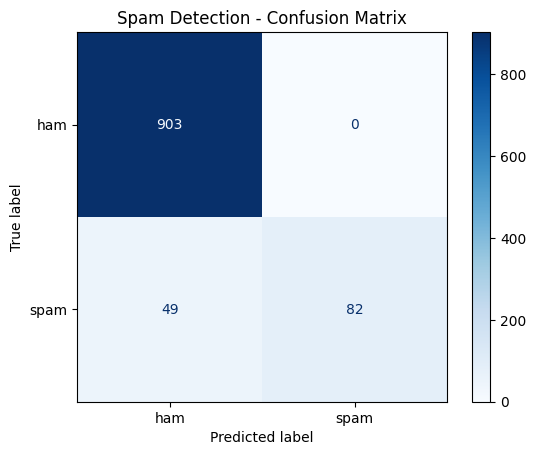

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["ham", "spam"],
    cmap="Blues"
)

plt.title("Spam Detection - Confusion Matrix")
plt.show()

we have no ham identified as spam: ham=903, spam as ham 49 and identified correctly as spam would b 82


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create the model
lr_model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

# Predict on the test set
y_lr_pred = lr_model.predict(X_test_tfidf)

# Evaluate the model
print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_lr_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_lr_pred))

Logistic Regression Accuracy: 0.9642166344294004

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       0.96      0.75      0.84       131

    accuracy                           0.96      1034
   macro avg       0.96      0.87      0.91      1034
weighted avg       0.96      0.96      0.96      1034



In [21]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# Create the model
svm_model = LinearSVC(random_state=42)

# Train the model
svm_model.fit(X_train_tfidf, y_train)

# Predict on the test set
y_svm_pred = svm_model.predict(X_test_tfidf)

# Evaluate the model
print("Linear SVM Accuracy:",
      accuracy_score(y_test, y_svm_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_svm_pred))

Linear SVM Accuracy: 0.9816247582205029

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       903
        spam       0.97      0.89      0.92       131

    accuracy                           0.98      1034
   macro avg       0.98      0.94      0.96      1034
weighted avg       0.98      0.98      0.98      1034



[[899   4]
 [ 15 116]]


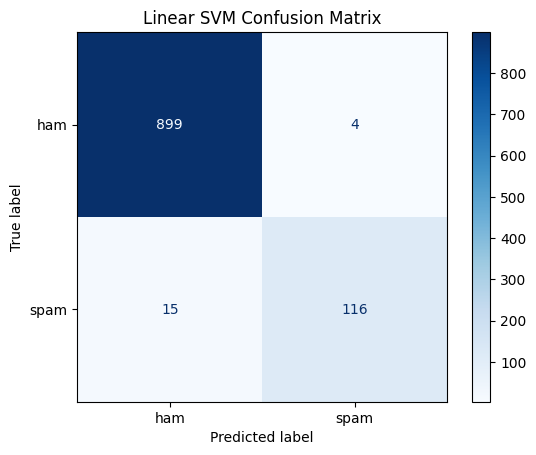

In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_svm_pred,
    labels=["ham", "spam"]
)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["ham", "spam"]
).plot(cmap="Blues")

plt.title("Linear SVM Confusion Matrix")
plt.show()

noticable difference from out other models:the trade off is small enough to let go 15 spams are labeled as ham and 4 hams are labeled as spam.


In [23]:
results = pd.DataFrame({
    "message": X_test.to_numpy(),
    "actual": y_test.to_numpy(),
    "predicted": y_svm_pred
})

mistakes = results[results["actual"] != results["predicted"]]

print("Total misclassified messages:", len(mistakes))
mistakes

Total misclassified messages: 19


,message,actual,predicted
95,Want explicit SEX in 30 secs? Ring 02073162414...,spam,ham
105,You will recieve your tone within the next 24h...,spam,ham
230,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE ...,spam,ham
293,Are you free now?can i call now?,ham,spam
308,Hi its LUCY Hubby at meetins all day Fri & I w...,spam,ham
326,Missed call alert. These numbers called but le...,spam,ham
327,K k:) sms chat with me.,ham,spam
398,Bought one ringtone and now getting texts cost...,spam,ham
437,Babe: U want me dont u baby! Im nasty and have...,spam,ham
486,In The Simpsons Movie released in July 2007 na...,spam,ham


In [24]:
pd.set_option("display.max_colwidth", None)

mistakes[["message", "actual", "predicted"]]

,message,actual,predicted
95,Want explicit SEX in 30 secs? Ring 02073162414 now! Costs 20p/min Gsex POBOX 2667 WC1N 3XX,spam,ham
105,You will recieve your tone within the next 24hrs. For Terms and conditions please see Channel U Teletext Pg 750,spam,ham
230,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT. BAILIFF DUE IN DAYS. I O £250 3 WANT £800,spam,ham
293,Are you free now?can i call now?,ham,spam
308,Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave msg 2day 09099726395 Lucy x Calls£1/minMobsmoreLKPOBOX177HP51FL,spam,ham
326,Missed call alert. These numbers called but left no message. 07008009200,spam,ham
327,K k:) sms chat with me.,ham,spam
398,Bought one ringtone and now getting texts costing 3 pound offering more tones etc,spam,ham
437,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XXX SLO(4msgs),spam,ham
486,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B or C)",spam,ham


In [25]:
missed_spam = mistakes[
    (mistakes["actual"] == "spam") &
    (mistakes["predicted"] == "ham")
]

for message in missed_spam["message"]:
    print(message)
    print("-" * 80)

Want explicit SEX in 30 secs? Ring 02073162414 now! Costs 20p/min Gsex POBOX 2667 WC1N 3XX
--------------------------------------------------------------------------------
You will recieve your tone within the next 24hrs. For Terms and conditions please see Channel U Teletext Pg 750
--------------------------------------------------------------------------------
ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT. BAILIFF DUE IN DAYS. I O £250 3 WANT £800
--------------------------------------------------------------------------------
Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave msg 2day 09099726395 Lucy x Calls£1/minMobsmoreLKPOBOX177HP51FL
--------------------------------------------------------------------------------
Missed call alert. These numbers called but left no message. 07008009200
--------------------------------------------------------------------------------

In [27]:
import pandas as pd

feature_names = vectorizer.get_feature_names_out()
weights = svm_model.coef_.T.flatten()

word_weights = pd.DataFrame({
    "word": feature_names,
    "weight": weights
})

print("Words most associated with SPAM:")
print(word_weights.sort_values("weight", ascending=False).head(20))

print("\nWords most associated with HAM:")
print(word_weights.sort_values("weight", ascending=True).head(20))

Words most associated with SPAM:
           word    weight
7030        txt  2.318458
7058         uk  1.774410
6728       text  1.714273
291        150p  1.687569
7578        www  1.676471
5666      reply  1.660179
524          50  1.614330
1740       chat  1.607275
1814      claim  1.585849
4498     mobile  1.557402
5973    service  1.409890
1601       call  1.353789
3489       http  1.319522
6436       stop  1.315827
1891        com  1.258659
285   146tf150p  1.255182
5741   ringtone  1.249836
1862         co  1.216257
7512        won  1.157226
7144     urgent  1.132667

Words most associated with HAM:
           word    weight
4359         me -1.105926
4613         my -0.904900
1624        can -0.885498
4068      liked -0.877007
7666        yup -0.820525
2995  fullonsms -0.795007
3214         gt -0.771285
4201         lt -0.747219
4111         ll -0.739127
6752       that -0.737147
5178      place -0.699395
3986      later -0.664498
1567        but -0.636971
2120         da -0.63285

In [28]:
# Get the first spam message that the model missed
message = missed_spam.iloc[0]["message"]

# Convert it using the TF-IDF vectorizer we already trained
message_tfidf = vectorizer.transform([message])

# Get the SVM's decision score
score = svm_model.decision_function(message_tfidf)[0]

print("Message:", message)
print("Actual label: spam")
print("Predicted label:", svm_model.predict(message_tfidf)[0])
print("Decision score:", score)

# Display the words in this message and their learned weights
present_features = message_tfidf.nonzero()[1]

message_words = pd.DataFrame({
    "word": feature_names[present_features],
    "tfidf": message_tfidf.data
})

message_words["weight"] = message_words["word"].map(
    word_weights.set_index("word")["weight"]
)

message_words["contribution"] = (
    message_words["tfidf"] * message_words["weight"]
)

print("\nFeature contributions:")
print(message_words.sort_values("contribution"))

Message: Want explicit SEX in 30 secs? Ring 02073162414 now! Costs 20p/min Gsex POBOX 2667 WC1N 3XX
Actual label: spam
Predicted label: ham
Decision score: -0.5330944720669605

Feature contributions:
    word     tfidf    weight  contribution
9   want  0.219782 -0.348794     -0.076659
1     30  0.351160 -0.215994     -0.075848
7   ring  0.335442 -0.175555     -0.058889
3     in  0.148423 -0.299502     -0.044453
2  costs  0.417001  0.020833      0.008687
0    20p  0.402423  0.184210      0.074131
8    sex  0.355990  0.218741      0.077870
5    now  0.175821  0.502510      0.088352
4    min  0.277566  0.496817      0.137900
6  pobox  0.351160  0.622472      0.218587


In [29]:
import numpy as np
import pandas as pd

# Convert the message's sparse TF-IDF matrix to a 1D array
message_tfidf = vectorizer.transform([message])
tfidf_values = message_tfidf.toarray().flatten()

# Get the corresponding SVM weights
weights = svm_model.coef_.flatten()

# Identify features present in the message
present_indices = np.flatnonzero(tfidf_values)

message_words = pd.DataFrame({
    "word": feature_names[present_indices],
    "tfidf": tfidf_values[present_indices],
    "weight": weights[present_indices]
})

message_words["contribution"] = (
    message_words["tfidf"] * message_words["weight"]
)

print(message_words.sort_values("contribution"))
print("\nSum of word contributions:",
      message_words["contribution"].sum())

print("SVM intercept:", svm_model.intercept_[0])
print("Actual decision score:",
      svm_model.decision_function(message_tfidf)[0])

    word     tfidf    weight  contribution
9   want  0.219782 -0.348794     -0.076659
1     30  0.351160 -0.215994     -0.075848
7   ring  0.335442 -0.175555     -0.058889
3     in  0.148423 -0.299502     -0.044453
2  costs  0.417001  0.020833      0.008687
0    20p  0.402423  0.184210      0.074131
8    sex  0.355990  0.218741      0.077870
5    now  0.175821  0.502510      0.088352
4    min  0.277566  0.496817      0.137900
6  pobox  0.351160  0.622472      0.218587

Sum of word contributions: 0.3496772108665843
SVM intercept: -0.8827716829335448
Actual decision score: -0.5330944720669605


In [30]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import make_scorer, f1_score

# Combine text vectorization and classification

svm_pipeline = Pipeline([
("tfidf", TfidfVectorizer()),
("svm", LinearSVC(random_state=42))
])

# Create 5 stratified folds

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate how well the model detects spam

spam_f1 = make_scorer(f1_score, pos_label="spam")

scores = cross_val_score(
svm_pipeline,
X_train,
y_train,
cv=cv,
scoring=spam_f1
)

print("Spam F1-score for each fold:", scores)
print("Mean Spam F1-score:", scores.mean())
print("Standard deviation:", scores.std())


Spam F1-score for each fold: [0.93401015 0.92857143 0.93939394 0.93137255 0.92462312]
Mean Spam F1-score: 0.9315942369694259
Standard deviation: 0.004989089182066527


In [31]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

# Create the final pipeline
final_model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("svm", LinearSVC(random_state=42))
])

# Train on all training data
final_model.fit(X_train, y_train)

print("Final model trained successfully!")

Final model trained successfully!


In [32]:
import joblib

joblib.dump(final_model, "spam_classifier.joblib")

print("Model saved successfully!")

Model saved successfully!


In [33]:
import joblib

# Load our saved pipeline
loaded_model = joblib.load("spam_classifier.joblib")

# New messages the model hasn't seen before
new_messages = [
    "Congratulations! You have won a free prize. Call now to claim!",
    "Hey, are we still meeting for lunch tomorrow?",
    "URGENT! You have been selected to receive a free gift. Reply NOW!",
    "Thanks for helping me with my assignment yesterday."
]

# Predict whether each message is spam or ham
predictions = loaded_model.predict(new_messages)

# Display the results
for message, prediction in zip(new_messages, predictions):
    print(f"Message: {message}")
    print(f"Prediction: {prediction}")
    print("-" * 60)

Message: Congratulations! You have won a free prize. Call now to claim!
Prediction: spam
------------------------------------------------------------
Message: Hey, are we still meeting for lunch tomorrow?
Prediction: ham
------------------------------------------------------------
Message: URGENT! You have been selected to receive a free gift. Reply NOW!
Prediction: spam
------------------------------------------------------------
Message: Thanks for helping me with my assignment yesterday.
Prediction: ham
------------------------------------------------------------
